# Fine-Tuning — Neural Net Classification Head
Requires `finetune_setup.ipynb` (produces `proj_out`).

Trains BrainOmni-tiny fine-tuning (last 1/2/3 blocks) with a small neural-net head and evaluates it three ways:
- **80/10/10** single split (val used for best-epoch selection)
- **70/15/15** single split (larger, more stable val/test)
- **5-fold CV** over all 148 subjects (the trustworthy metric)

Recipe (official BrainOmni): AdamW, differential LR (backbone 1e-5 / head 1e-4), warmup-cosine, weight decay 0.05, label smoothing 0.1, best epoch = min val loss.

Saves `finetune_shared.pt` so `finetune_logreg.ipynb` reuses the same fine-tuned blocks.

In [7]:
import os, sys, json, math
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'  # avoid libomp double-init crash
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score)
import matplotlib.pyplot as plt
from tqdm import tqdm

sys.path.insert(0, '/Users/faenegoro/Documents/Neuroimaging/BrainOmni')
from brainomni.model import BrainOmni

device = torch.device('mps') if torch.backends.mps.is_available() else torch.device('cpu')
print('Device:', device)

Device: mps


In [8]:
CKPT_PATH = '/Users/faenegoro/Documents/Neuroimaging/BrainOmni/ckpt_collection/base'
SAVE_DIR  = '../data/preprocessed'
OUT_DIR   = '../results/figures'
os.makedirs(OUT_DIR, exist_ok=True)

with open(os.path.join(CKPT_PATH, 'model_cfg.json')) as f:
    model_config = json.load(f)
base_checkpoint = torch.load(
    os.path.join(CKPT_PATH, 'BrainOmni.pt'), map_location='cpu', weights_only=True
)

proj_out1 = np.load(os.path.join(SAVE_DIR, 'proj_out1_base.npy'))  # (N, 16, NT, 256) tokenizer output
proj_out2 = np.load(os.path.join(SAVE_DIR, 'proj_out2_base.npy'))
labels    = np.load(os.path.join(SAVE_DIR, 'labels.npy'))
N = len(labels)

# Baselines (5-fold CV) from evaluation.ipynb
FROZEN_CV    = 0.831
HANDCRAFT_CV = 0.872

nn_split = {}  # filled by the splits cell; stays empty if you run CV only

def make_split(labels, holdout, seed=123):
    """Stratified split. holdout=0.10 -> 80/10/10; holdout=0.15 -> 70/15/15."""
    idx = np.arange(len(labels))
    tr, tmp = train_test_split(idx, test_size=2 * holdout, stratify=labels, random_state=seed)
    va, te  = train_test_split(tmp, test_size=0.5, stratify=labels[tmp], random_state=seed)
    return tr, va, te

SPLITS = {'80/10/10': make_split(labels, 0.10),
          '70/15/15': make_split(labels, 0.15)}
for name, (tr, va, te) in SPLITS.items():
    print(f'{name}: train {len(tr)} | val {len(va)} | test {len(te)}')

80/10/10: train 118 | val 15 | test 15
70/15/15: train 103 | val 22 | test 23


In [9]:
class CachedMEGDataset(Dataset):
    def __init__(self, indices, cached1, cached2, labels):
        self.indices, self.cached1, self.cached2, self.labels = indices, cached1, cached2, labels
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        idx = self.indices[i]
        return self.cached1[idx], self.cached2[idx], torch.tensor(self.labels[idx], dtype=torch.long)

class FinetuneClassifier(nn.Module):
    def __init__(self, encoder_blocks, hidden_dim=512):
        super().__init__()
        self.blocks = encoder_blocks
        self.head = nn.Sequential(
            nn.Linear(hidden_dim * 16, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 2))
    def forward(self, x1, x2):
        x1, x2 = x1.to(device), x2.to(device)
        for block in self.blocks:
            x1 = block(x1); x2 = block(x2)
        x1 = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        x2 = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        return self.head(((x1 + x2) / 2).flatten(1))

def make_warmup_cosine(optimizer, total_steps, warmup_ratio=0.1, warmup_min=0.1, cos_min=0.1):
    warmup_steps = max(1, int(total_steps * warmup_ratio))
    def lr_lambda(step):
        if step < warmup_steps:
            return warmup_min + (1 - warmup_min) * step / warmup_steps
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return cos_min + (1 - cos_min) * 0.5 * (1 + math.cos(math.pi * prog))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

def fresh_frozen_model():
    m = BrainOmni(**model_config)
    m.load_state_dict(base_checkpoint, strict=False)
    for p in m.parameters():
        p.requires_grad = False
    return m.to(device).eval()

def cache_frozen(model, n_frozen):
    """Run every subject through frozen blocks 0..n_frozen-1 (tokenizer output is proj_out)."""
    c1, c2 = [], []
    with torch.no_grad():
        for i in range(N):
            x1 = torch.tensor(proj_out1[i]).unsqueeze(0).to(device)
            x2 = torch.tensor(proj_out2[i]).unsqueeze(0).to(device)
            for block in list(model.blocks)[:n_frozen]:
                x1 = block(x1); x2 = block(x2)
            c1.append(x1.squeeze(0).cpu()); c2.append(x2.squeeze(0).cpu())
    return c1, c2

def extract_features(model, ft_blocks, n_frozen):
    """Every subject through frozen + fine-tuned blocks -> (N, 4096) features (for LR)."""
    feats = []
    with torch.no_grad():
        for i in range(N):
            x1 = torch.tensor(proj_out1[i]).unsqueeze(0).to(device)
            x2 = torch.tensor(proj_out2[i]).unsqueeze(0).to(device)
            for block in list(model.blocks)[:n_frozen]:
                x1 = block(x1); x2 = block(x2)
            for block in ft_blocks:
                x1 = block(x1); x2 = block(x2)
            x1 = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2).flatten(1)
            x2 = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2).flatten(1)
            feats.append(((x1 + x2) / 2).squeeze(0).cpu().numpy())
    return np.array(feats)

BACKBONE_LR, HEAD_LR = 1e-5, 1e-4  # official recipe: pretrained backbone small, random head 10x

print('Model helpers ready.')

Model helpers ready.


In [10]:
def train_finetune(n_frozen, tr_idx, va_idx, cached1, cached2, model,
                   max_epochs=200, patience=10**9, use_val=True, monitor_idx=None):
    """Fine-tune the last (11-n_frozen) blocks + NN head. Best epoch = lowest val loss.
    patience defaults huge so the FULL curve is drawn (no early stop); best-epoch weights
    are still restored for the reported number. monitor_idx is an optional held-out set
    logged each epoch for the picture only (never used for selection or stopping)."""
    train_loader = DataLoader(CachedMEGDataset(tr_idx, cached1, cached2, labels), batch_size=8, shuffle=True)
    val_loader   = DataLoader(CachedMEGDataset(va_idx, cached1, cached2, labels), batch_size=8) if use_val else None
    mon_loader   = DataLoader(CachedMEGDataset(monitor_idx, cached1, cached2, labels), batch_size=8) if monitor_idx is not None else None

    unfrozen = nn.ModuleList(list(model.blocks)[n_frozen:-1])
    for p in unfrozen.parameters():
        p.requires_grad = True
    ft = FinetuneClassifier(unfrozen, 512).to(device)
    opt = torch.optim.AdamW([
        {'params': ft.blocks.parameters(), 'lr': BACKBONE_LR, 'weight_decay': 0.05},
        {'params': ft.head.parameters(),   'lr': HEAD_LR,     'weight_decay': 0.05},
    ], betas=(0.9, 0.99), eps=1e-6)
    sched = make_warmup_cosine(opt, max_epochs * len(train_loader))
    crit  = nn.CrossEntropyLoss(label_smoothing=0.1)

    def eval_loader(loader):
        ft.eval(); p, t, ls = [], [], 0.0
        with torch.no_grad():
            for x1, x2, y in loader:
                out = ft(x1, x2); ls += crit(out, y.to(device)).item()
                p.extend(out.argmax(1).cpu().numpy()); t.extend(y.numpy())
        return accuracy_score(t, p), ls / len(loader)

    best_vl, best_va, best_ep, pc, best_w = float('inf'), 0, 0, 0, None
    ta, vacc, tl, vl, mona, monl = [], [], [], [], [], []
    for epoch in range(max_epochs):
        ft.train(); preds, trues, el = [], [], 0.0
        for x1, x2, y in train_loader:
            opt.zero_grad(); out = ft(x1, x2); loss = crit(out, y.to(device)); loss.backward()
            torch.nn.utils.clip_grad_norm_(ft.parameters(), 1.0); opt.step(); sched.step()
            el += loss.item(); preds.extend(out.argmax(1).cpu().numpy()); trues.extend(y.numpy())
        tra, trl = accuracy_score(trues, preds), el / len(train_loader)

        if val_loader is not None:
            va_, vll = eval_loader(val_loader)
        else:
            va_, vll = 0.0, trl
        if mon_loader is not None:
            ma_, mll = eval_loader(mon_loader); mona.append(ma_); monl.append(mll)

        ta.append(tra); vacc.append(va_); tl.append(trl); vl.append(vll)
        if vll < best_vl - 1e-4:
            best_vl, best_va, best_ep = vll, va_, epoch + 1
            best_w = {k: v.clone() for k, v in ft.state_dict().items()}; pc = 0
        else:
            pc += 1
            if pc >= patience and use_val:
                break
    if best_w is not None:
        ft.load_state_dict(best_w)
    hist = {'best_ep': best_ep, 'best_val': best_va, 'best_weights': best_w,
            'train_accs': ta, 'val_accs': vacc, 'train_losses': tl, 'val_losses': vl}
    if mon_loader is not None:
        hist['mon_accs'] = mona; hist['mon_losses'] = monl
    return ft, hist

def nn_predict(ft, idx, cached1, cached2):
    ft.eval(); trues, preds, probs = [], [], []
    with torch.no_grad():
        for i in idx:
            out = ft(cached1[i].unsqueeze(0), cached2[i].unsqueeze(0))
            probs.append(torch.softmax(out, 1)[0, 1].item())
            preds.append(out.argmax(1).item()); trues.append(labels[i])
    return np.array(trues), np.array(preds), np.array(probs)

def run_split(n_frozen, split):
    tr, va, te = split
    model = fresh_frozen_model()
    c1, c2 = cache_frozen(model, n_frozen)
    ft, curves = train_finetune(n_frozen, tr, va, c1, c2, model, max_epochs=200, patience=10**9, monitor_idx=te)
    yt, yp, _ = nn_predict(ft, te, c1, c2)
    curves['test_acc'] = accuracy_score(yt, yp)
    curves['n_unfrozen'] = 11 - n_frozen
    return curves

print('Split-training helpers ready.')

Split-training helpers ready.


In [11]:
def run_cv(n_frozen, cv_epochs=200, n_splits=5, seed=123, inner_val=0.15):
    """5-fold CV. Inside each fold, carve an inner validation set out of the training
    subjects; select the epoch on THAT (never the test fold). The held-out test fold is
    logged each epoch (monitor) only for the learning-curve picture. Reads out both the
    NN head and an LR head on the held-out fold so the two methods stay comparable."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof_true = np.full(N, -1, int)
    nn_pred, nn_prob = np.zeros(N, int), np.zeros(N)
    lr_pred, lr_prob = np.zeros(N, int), np.zeros(N)
    nn_fold, lr_fold, fold_hist = [], [], []

    for fold, (tr, te) in enumerate(skf.split(np.arange(N), labels)):
        inner_tr, inner_va = train_test_split(tr, test_size=inner_val,
                                              stratify=labels[tr], random_state=seed)
        model = fresh_frozen_model()
        c1, c2 = cache_frozen(model, n_frozen)
        ft, hist = train_finetune(n_frozen, inner_tr, inner_va, c1, c2, model,
                                  max_epochs=cv_epochs, patience=cv_epochs,
                                  use_val=True, monitor_idx=te)
        fold_hist.append(hist)
        # NN head out-of-fold (weights restored at best inner-val epoch)
        yt, yp, ypr = nn_predict(ft, te, c1, c2)
        nn_pred[te], nn_prob[te], oof_true[te] = yp, ypr, labels[te]
        nn_fold.append(accuracy_score(labels[te], yp))
        # LR head out-of-fold (same fine-tuned blocks)
        feats = extract_features(model, ft.blocks, n_frozen)
        lr = LogisticRegression(max_iter=1000); lr.fit(feats[tr], labels[tr])
        lr_pred[te] = lr.predict(feats[te]); lr_prob[te] = lr.predict_proba(feats[te])[:, 1]
        lr_fold.append(accuracy_score(labels[te], lr_pred[te]))
        print(f'  n_frozen={n_frozen} fold {fold+1}: best_ep {hist["best_ep"]} | NN {nn_fold[-1]:.3f} | LR {lr_fold[-1]:.3f}')

    return {'nn_mean': float(np.mean(nn_fold)), 'nn_folds': nn_fold,
            'lr_mean': float(np.mean(lr_fold)), 'lr_folds': lr_fold,
            'y_true': oof_true, 'nn_pred': nn_pred, 'nn_prob': nn_prob,
            'lr_pred': lr_pred, 'lr_prob': lr_prob, 'fold_hist': fold_hist}

print('CV helper ready.')

CV helper ready.


## Train on the two single splits

In [12]:
# Fine-tune on the two fixed splits (80/10/10 and 70/15/15), last 1/2/3 blocks
nn_split = {name: {} for name in SPLITS}
for name, split in SPLITS.items():
    for n_frozen in [10, 9, 8]:
        print(f'=== NN head | {name} | last {11-n_frozen} block(s) ===')
        nn_split[name][n_frozen] = run_split(n_frozen, split)
        print(f'   best epoch {nn_split[name][n_frozen]["best_ep"]} | test {nn_split[name][n_frozen]["test_acc"]:.3f}')

=== NN head | 80/10/10 | last 1 block(s) ===


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


   best epoch 174 | test 0.800
=== NN head | 80/10/10 | last 2 block(s) ===


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


   best epoch 102 | test 0.733
=== NN head | 80/10/10 | last 3 block(s) ===


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


... (3 outputs left out)

/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


   best epoch 17 | test 0.913
=== NN head | 70/15/15 | last 3 block(s) ===


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


   best epoch 16 | test 0.870


## 5-fold cross-validation

In [13]:
# 5-fold CV (also records LR out-of-fold predictions for the logreg notebook)
cv_results = {}
for n_frozen in [10, 9, 8]:
    print(f'=== 5-fold CV | last {11-n_frozen} block(s) ===')
    cv_results[n_frozen] = run_cv(n_frozen)
    print(f'   NN mean {cv_results[n_frozen]["nn_mean"]:.3f} | LR mean {cv_results[n_frozen]["lr_mean"]:.3f}')

=== 5-fold CV | last 1 block(s) ===


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  n_frozen=10 fold 1: best_ep 37 | NN 0.633 | LR 0.667


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  n_frozen=10 fold 2: best_ep 69 | NN 0.900 | LR 0.933


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


... (21 outputs left out)

/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  n_frozen=8 fold 4: best_ep 140 | NN 0.759 | LR 0.793


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  n_frozen=8 fold 5: best_ep 102 | NN 0.793 | LR 0.759
   NN mean 0.797 | LR mean 0.797


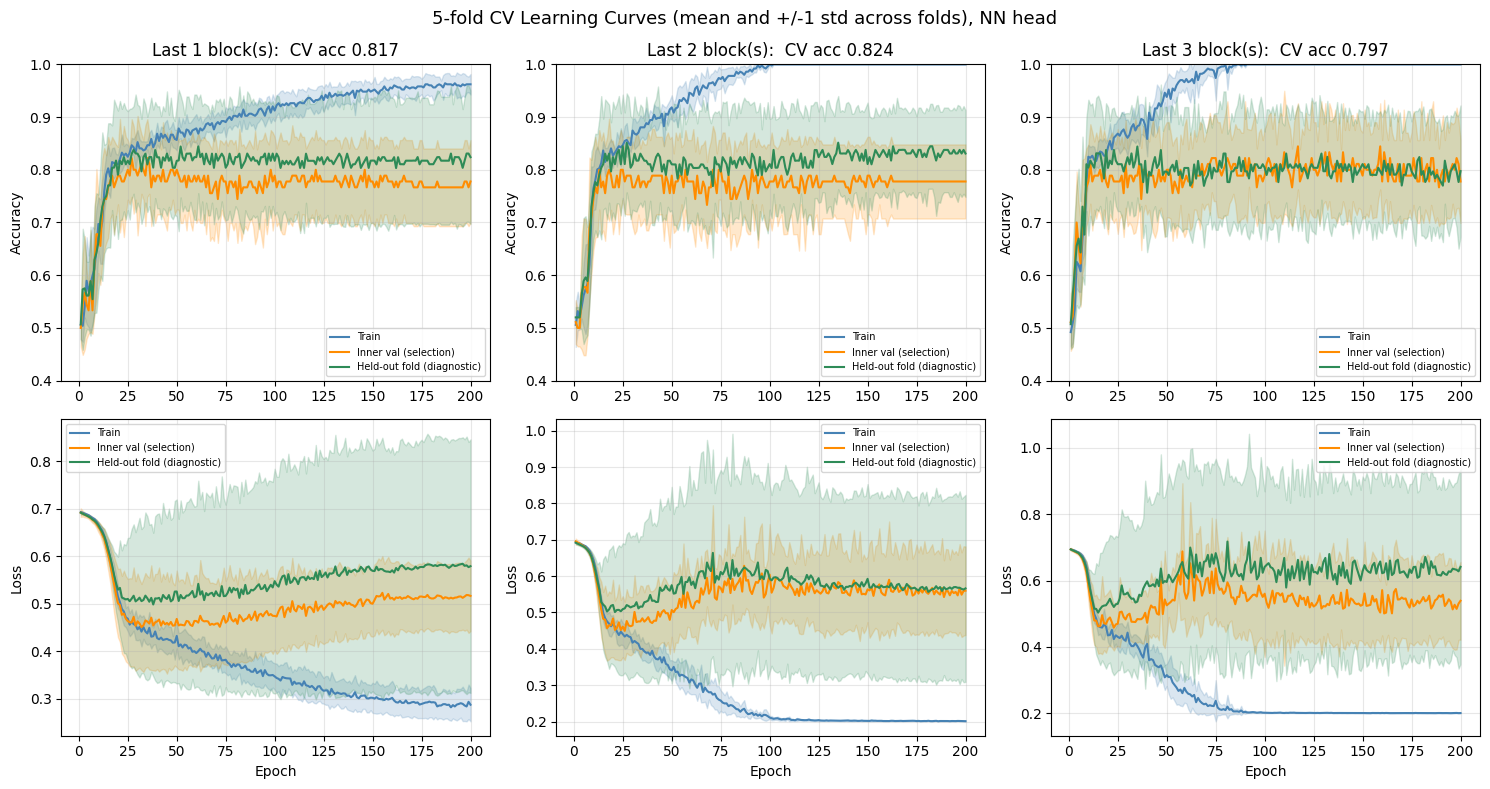

Saved nn_curves_cv.png


In [14]:
# 5-fold CV learning curves: mean and +/-1 std band across the 5 folds.
# Blue = train, orange = inner validation (used to pick the epoch),
# green = held-out test fold (diagnostic only, NOT used for selection).
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, nf in enumerate([10, 9, 8]):
    hs = cv_results[nf]['fold_hist']
    L  = min(len(h['train_losses']) for h in hs)
    ep = np.arange(1, L + 1)
    def band(ax, key, color, label):
        M = np.array([h[key][:L] for h in hs])
        m, s = M.mean(0), M.std(0)
        ax.plot(ep, m, color=color, label=label); ax.fill_between(ep, m - s, m + s, color=color, alpha=0.2)
    band(axes[0, col], 'train_accs', 'steelblue',  'Train')
    band(axes[0, col], 'val_accs',   'darkorange', 'Inner val (selection)')
    band(axes[0, col], 'mon_accs',   'seagreen',   'Held-out fold (diagnostic)')
    axes[0, col].set_title(f'Last {11-nf} block(s):  CV acc {cv_results[nf]["nn_mean"]:.3f}')
    axes[0, col].set_ylabel('Accuracy'); axes[0, col].set_ylim(0.4, 1.0)
    axes[0, col].legend(fontsize=7); axes[0, col].grid(alpha=0.3)
    band(axes[1, col], 'train_losses', 'steelblue',  'Train')
    band(axes[1, col], 'val_losses',   'darkorange', 'Inner val (selection)')
    band(axes[1, col], 'mon_losses',   'seagreen',   'Held-out fold (diagnostic)')
    axes[1, col].set_xlabel('Epoch'); axes[1, col].set_ylabel('Loss')
    axes[1, col].legend(fontsize=7); axes[1, col].grid(alpha=0.3)
fig.suptitle('5-fold CV Learning Curves (mean and +/-1 std across folds), NN head', fontsize=13)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'nn_curves_cv_base.png'), dpi=150); plt.show()
print('Saved nn_curves_cv.png')

## Comparison chart (NN head, 3 evaluations)

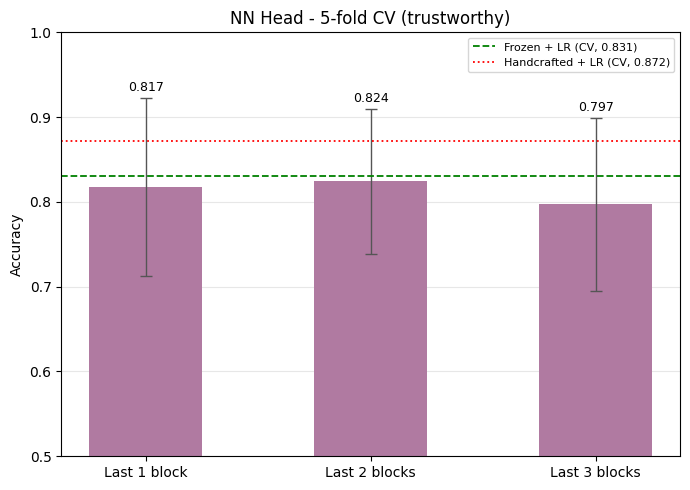

Saved nn_comparison_cv_base.png


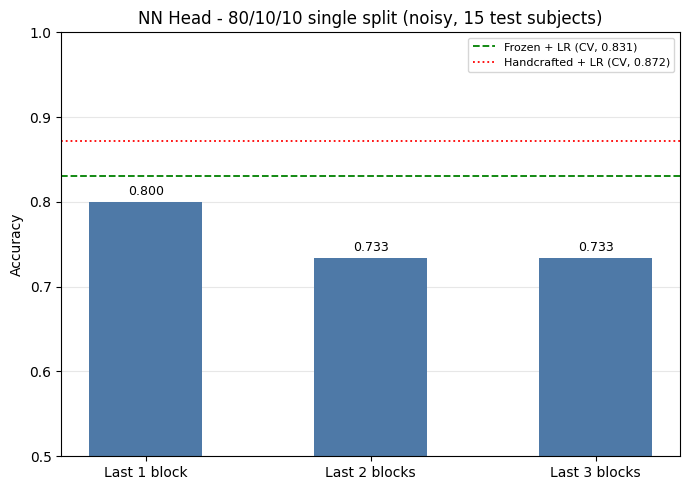

Saved nn_comparison_80-10-10_base.png


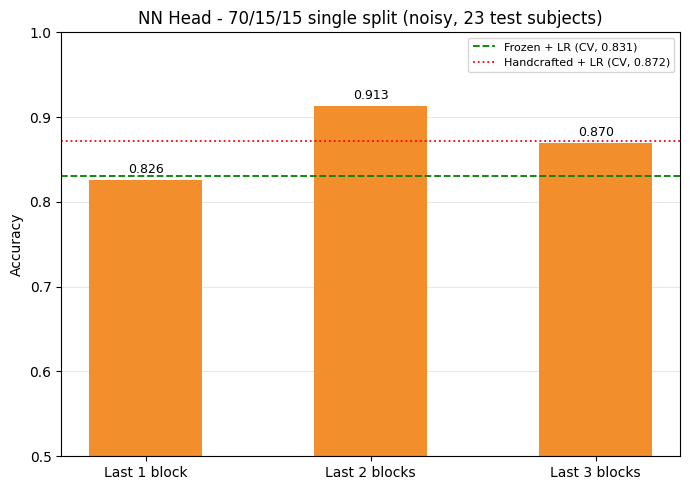

Saved nn_comparison_70-15-15_base.png


In [15]:
# Three separate comparison charts, one per evaluation method.
# CV chart always; the two single-split charts only if the splits were run.
def _barchart(vals, color, title, fname, errs=None, n_test=None):
    x = np.arange(3)
    fig, ax = plt.subplots(figsize=(7, 5))
    b = ax.bar(x, vals, 0.5, color=color, yerr=errs, capsize=4,
               error_kw=(dict(lw=1, ecolor='#555') if errs is not None else None))
    ax.bar_label(b, fmt='%.3f', fontsize=9, padding=3)
    ax.axhline(FROZEN_CV,    color='green', ls='--', lw=1.3, label='Frozen + LR (CV, 0.831)')
    ax.axhline(HANDCRAFT_CV, color='red',   ls=':',  lw=1.3, label='Handcrafted + LR (CV, 0.872)')
    ax.set_xticks(x); ax.set_xticklabels(['Last 1 block', 'Last 2 blocks', 'Last 3 blocks'])
    ax.set_ylabel('Accuracy'); ax.set_ylim(0.5, 1.0)
    ax.set_title(title); ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3); ax.set_axisbelow(True)
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, fname), dpi=150); plt.show()
    print('Saved', fname)

# 1) 5-fold CV (trustworthy, has error bars)
cv_vals = [cv_results[nf]['nn_mean'] for nf in [10, 9, 8]]
cv_err  = [np.std(cv_results[nf]['nn_folds']) for nf in [10, 9, 8]]
_barchart(cv_vals, '#B07AA1', 'NN Head - 5-fold CV (trustworthy)', 'nn_comparison_cv_base.png', errs=cv_err)

# 2) & 3) single splits (noisy; only if run)
if nn_split:
    for name, fname, color in [('80/10/10', 'nn_comparison_80-10-10_base.png', '#4E79A7'),
                               ('70/15/15', 'nn_comparison_70-15-15_base.png', '#F28E2B')]:
        vals = [nn_split[name][nf]['test_acc'] for nf in [10, 9, 8]]
        n_test = len(SPLITS[name][2])
        _barchart(vals, color, f'NN Head - {name} single split (noisy, {n_test} test subjects)', fname)
else:
    print('Splits not run (CV-only) - skipping the 80/10/10 and 70/15/15 charts.')

## Learning curves

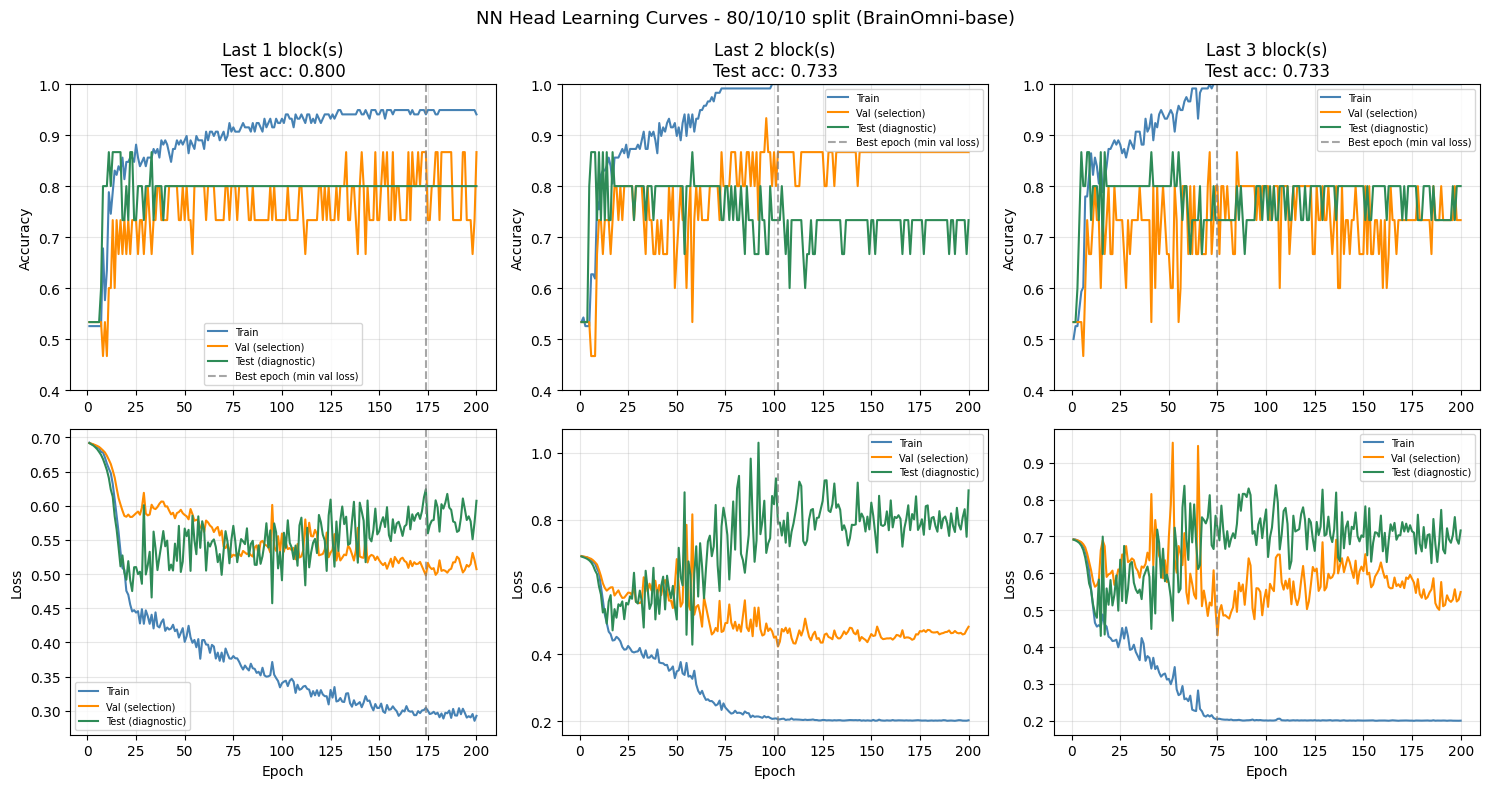

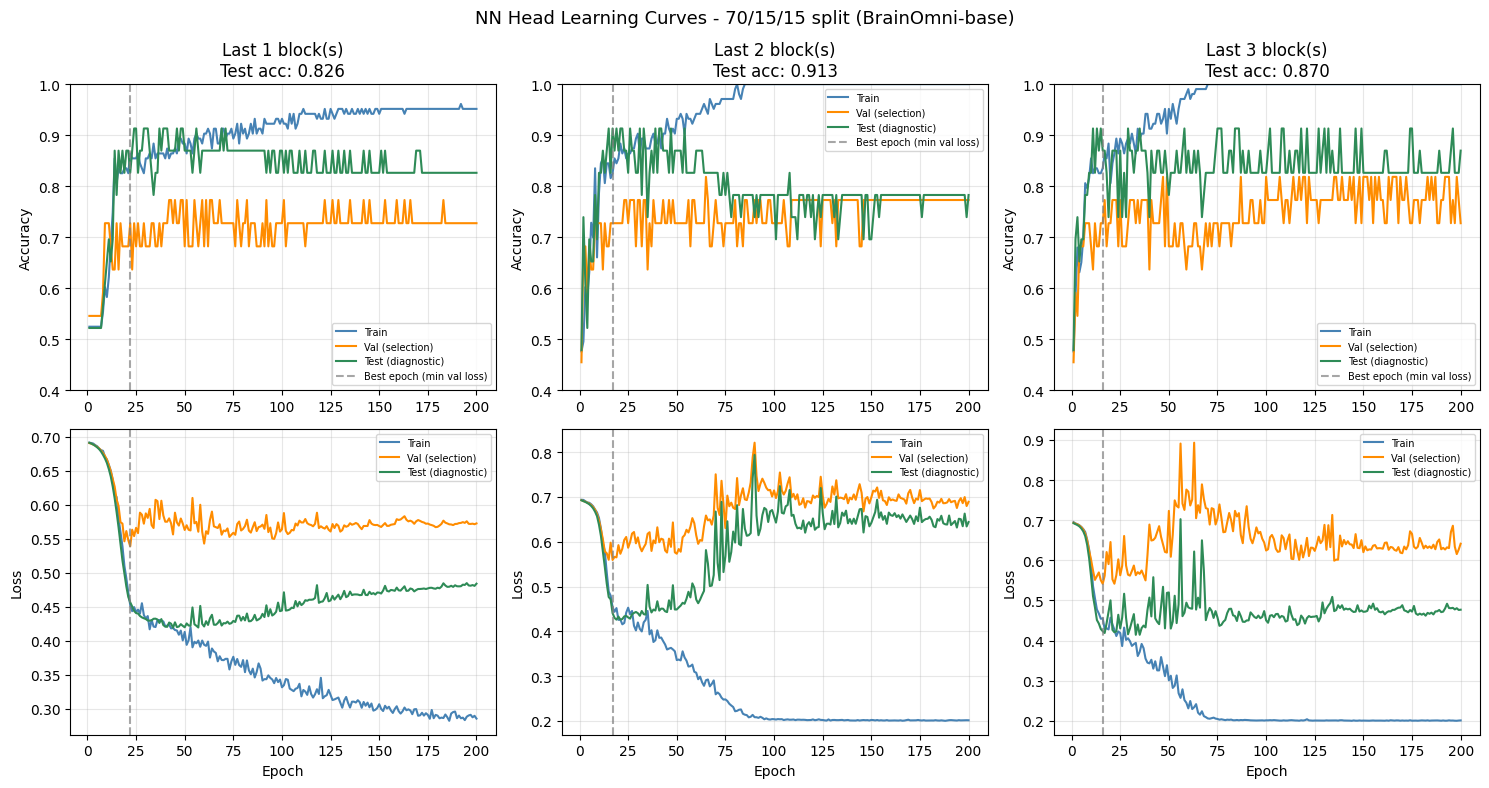

Saved learning-curve figures.


In [16]:
# Split learning curves (NN head): Train / Val / Test per epoch. Skipped if you ran CV only.
# Test (green) is the held-out split, monitored each epoch as a diagnostic only
# (the epoch is still chosen on Val loss, never on Test).
if not nn_split:
    print('Splits not run (CV-only) - skipping split learning-curve figures.')
else:
    for name in ['80/10/10', '70/15/15']:
        fig, axes = plt.subplots(2, 3, figsize=(15, 8))
        for col, nf in enumerate([10, 9, 8]):
            r = nn_split[name][nf]; ep = range(1, len(r['train_accs'])+1)
            axes[0, col].plot(ep, r['train_accs'], color='steelblue',  label='Train')
            axes[0, col].plot(ep, r['val_accs'],   color='darkorange', label='Val (selection)')
            if 'mon_accs' in r:
                axes[0, col].plot(ep, r['mon_accs'], color='seagreen', label='Test (diagnostic)')
            axes[0, col].axvline(r['best_ep'], color='gray', ls='--', alpha=0.7, label='Best epoch (min val loss)')
            axes[0, col].set_title(f'Last {11-nf} block(s)\nTest acc: {r["test_acc"]:.3f}')
            axes[0, col].set_ylabel('Accuracy'); axes[0, col].set_ylim(0.4, 1.0)
            axes[0, col].legend(fontsize=7); axes[0, col].grid(alpha=0.3)
            axes[1, col].plot(ep, r['train_losses'], color='steelblue',  label='Train')
            axes[1, col].plot(ep, r['val_losses'],   color='darkorange', label='Val (selection)')
            if 'mon_losses' in r:
                axes[1, col].plot(ep, r['mon_losses'], color='seagreen', label='Test (diagnostic)')
            axes[1, col].axvline(r['best_ep'], color='gray', ls='--', alpha=0.7)
            axes[1, col].set_xlabel('Epoch'); axes[1, col].set_ylabel('Loss')
            axes[1, col].legend(fontsize=7); axes[1, col].grid(alpha=0.3)
        fig.suptitle(f'NN Head Learning Curves - {name} split (BrainOmni-base)', fontsize=13)
        plt.tight_layout()
        plt.savefig(os.path.join(OUT_DIR, f'nn_curves_{name.replace("/","-")}_base.png'), dpi=150)
        plt.show()
    print('Saved learning-curve figures.')

## Confusion matrices (5-fold CV)

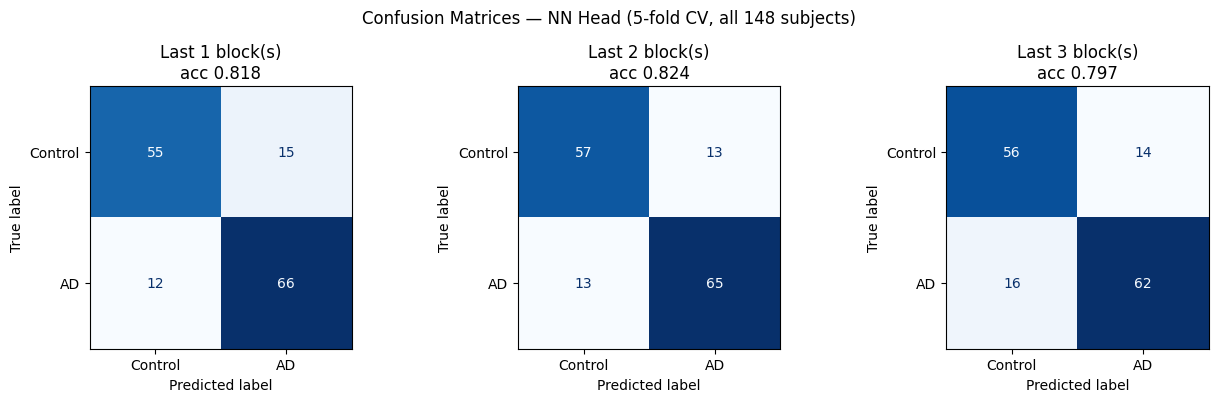

Saved nn_confusion_cv.png


In [17]:
# Confusion matrices — 5-fold CV (all 148 subjects), NN head
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for col, nf in enumerate([10, 9, 8]):
    cv = cv_results[nf]
    ConfusionMatrixDisplay(confusion_matrix(cv['y_true'], cv['nn_pred']),
                           display_labels=['Control', 'AD']).plot(ax=axes[col], colorbar=False, cmap='Blues')
    axes[col].set_title(f'Last {11-nf} block(s)\nacc {accuracy_score(cv["y_true"], cv["nn_pred"]):.3f}')
fig.suptitle('Confusion Matrices — NN Head (5-fold CV, all 148 subjects)', fontsize=12)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'nn_confusion_cv_base.png'), dpi=150); plt.show()
print('Saved nn_confusion_cv.png')

## ROC curves (5-fold CV)

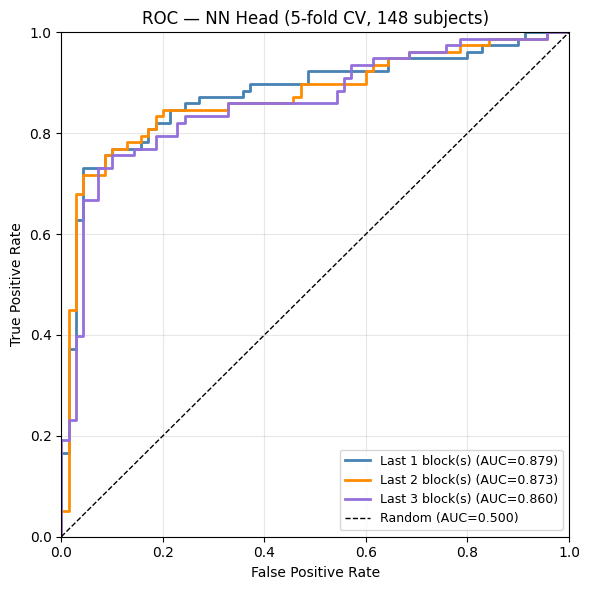

Saved nn_roc_cv.png


In [18]:
# ROC — 5-fold CV (all 148 subjects), NN head
fig, ax = plt.subplots(figsize=(6, 6))
for nf, color in zip([10, 9, 8], ['steelblue', 'darkorange', 'mediumpurple']):
    cv = cv_results[nf]
    fpr, tpr, _ = roc_curve(cv['y_true'], cv['nn_prob'])
    ax.plot(fpr, tpr, color=color, lw=2, label=f'Last {11-nf} block(s) (AUC={roc_auc_score(cv["y_true"], cv["nn_prob"]):.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (AUC=0.500)')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC — NN Head (5-fold CV, 148 subjects)')
ax.legend(fontsize=9, loc='lower right'); ax.grid(alpha=0.3); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'nn_roc_cv_base.png'), dpi=150); plt.show()
print('Saved nn_roc_cv.png')

## Save shared results

In [19]:
# Save what the logreg notebook needs. CV is always saved; nn_split is empty if you ran CV only.
save = {
    'cv':       cv_results,
    'splits':   {name: tuple(np.asarray(a) for a in sp) for name, sp in SPLITS.items()},
    'nn_split': ({name: {nf: {k: v for k, v in r.items()} for nf, r in cfgs.items()}
                  for name, cfgs in nn_split.items()} if nn_split else {}),
}
torch.save(save, os.path.join(SAVE_DIR, 'finetune_shared_base.pt'))
print('Saved finetune_shared_base.pt | keys:', list(save.keys()), '| nn_split configs:', len(save['nn_split']))

Saved finetune_shared_base.pt | keys: ['cv', 'splits', 'nn_split'] | nn_split configs: 2
